<a href="https://colab.research.google.com/github/Faheemmundoli/codeanatomy-main/blob/main/Lab_8%2C_9_%26_10_SVM%2C_KNN%2C_Model_Evaluation_and_Hyperparameter_Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Faheem M 2427010572

# Lab 8, 9 & 10: SVM, KNN, Model Evaluation and Hyperparameter Tuning

### Objectives:
1. Implement linear and kernel SVM classifiers and compare kernels.
2. Implement KNN and study the effect of K and distance metrics.
3. Evaluate models using accuracy, precision, recall, F1-score, ROC-AUC and cross-validation.
4. Tune hyperparameters using Grid Search and Random Search.

## Loading and Preparing the Data :
The Breast Cancer dataset has 569 samples and 30 features. The target is 0 (malignant) or 1 (benign). The data is split 80% for training and 20% for testing, and the features are standardized because SVM and KNN depend on distances.

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score)

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print(X.shape)
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

(569, 30)
target
1    357
0    212
Name: count, dtype: int64


## 1. SVM with Different Kernels :
SVM finds the line (hyperplane) that separates the two classes with the widest margin. A linear kernel uses a straight boundary. Poly, RBF and sigmoid kernels allow curved boundaries. The kernels are compared on training and testing accuracy.

In [ ]:
results = []
for kernel in ['linear', 'poly', 'rbf', 'sigmoid']:
    model = SVC(kernel=kernel)
    model.fit(X_train, y_train)
    results.append([kernel, model.score(X_train, y_train), model.score(X_test, y_test)])

pd.DataFrame(results, columns=['Kernel', 'Train Accuracy', 'Test Accuracy']).round(3)

,Kernel,Train Accuracy,Test Accuracy
0,linear,0.991,0.974
1,poly,0.916,0.912
2,rbf,0.982,0.982
3,sigmoid,0.956,0.930


## 2. KNN: Effect of K :
KNN classifies a point by looking at its K nearest neighbours and taking the majority class. A very small K is sensitive to noise (overfitting) and a very large K is too smooth (underfitting).

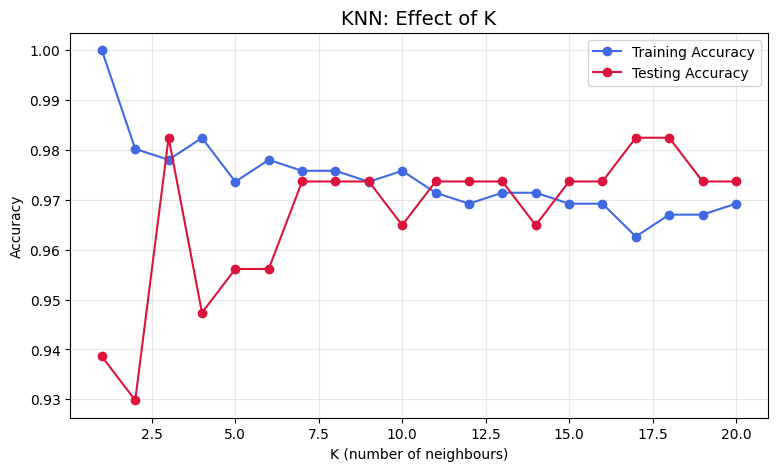

In [ ]:
k_range = range(1, 21)
train_acc, test_acc = [], []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    train_acc.append(knn.score(X_train, y_train))
    test_acc.append(knn.score(X_test, y_test))

plt.figure(figsize=(9, 5))
plt.plot(k_range, train_acc, marker='o', color='royalblue', label='Training Accuracy')
plt.plot(k_range, test_acc, marker='o', color='crimson', label='Testing Accuracy')
plt.title('KNN: Effect of K', fontsize=14)
plt.xlabel('K (number of neighbours)')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 3. KNN: Effect of Distance Metric :
The distance measure decides which points count as near. Euclidean is the straight-line distance, Manhattan adds the differences along each axis, and Chebyshev takes the largest single difference.

In [ ]:
rows = []
for metric in ['euclidean', 'manhattan', 'chebyshev']:
    knn = KNeighborsClassifier(n_neighbors=5, metric=metric)
    knn.fit(X_train, y_train)
    rows.append([metric, knn.score(X_test, y_test)])

pd.DataFrame(rows, columns=['Distance Metric', 'Test Accuracy']).round(3)

,Distance Metric,Test Accuracy
0,euclidean,0.956
1,manhattan,0.965
2,chebyshev,0.947


## 4. Evaluation Metrics :
SVM (RBF kernel) and KNN (K = 5) are compared using accuracy, precision, recall, F1-score and ROC-AUC.

In [ ]:
svm = SVC(kernel='rbf', probability=True, random_state=42).fit(X_train, y_train)
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)

rows = []
for name, model in [('SVM', svm), ('KNN', knn)]:
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    rows.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred),
                 recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, prob)])

pd.DataFrame(rows, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']).round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,SVM,0.982,0.986,0.986,0.986,0.995
1,KNN,0.956,0.959,0.972,0.966,0.979


## 5. Confusion Matrix and ROC Curve :
The confusion matrix shows correct and wrong predictions for each class. The ROC curve plots the true positive rate against the false positive rate, and a curve closer to the top-left corner means a better model.

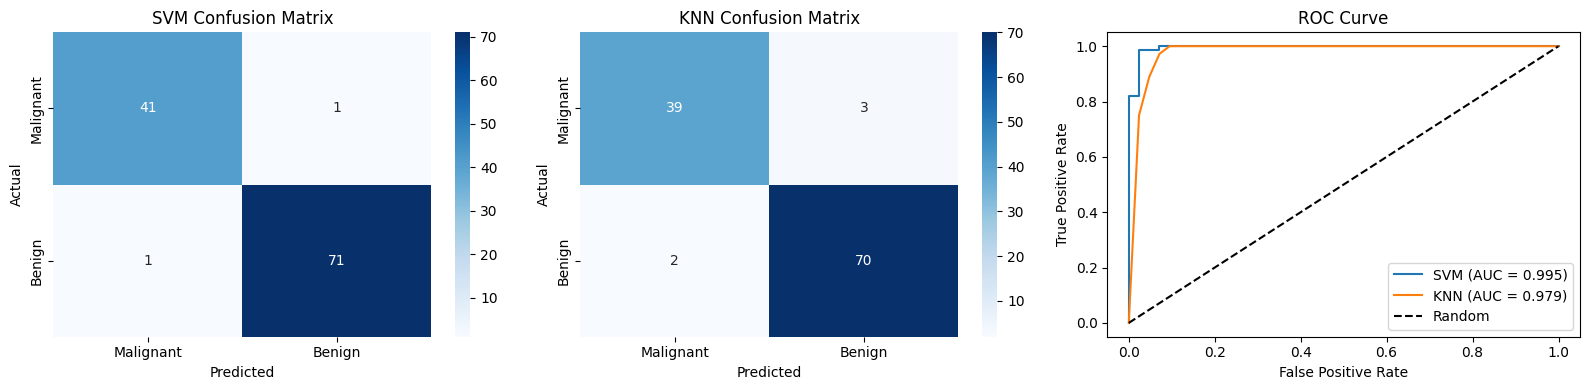

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

for i, (name, model) in enumerate([('SVM', svm), ('KNN', knn)]):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[i],
                xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
    ax[i].set_title(f'{name} Confusion Matrix')
    ax[i].set_xlabel('Predicted')
    ax[i].set_ylabel('Actual')

for name, model in [('SVM', svm), ('KNN', knn)]:
    prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[2].plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, prob):.3f})')
ax[2].plot([0, 1], [0, 1], 'k--', label='Random')
ax[2].set_title('ROC Curve')
ax[2].set_xlabel('False Positive Rate')
ax[2].set_ylabel('True Positive Rate')
ax[2].legend()

plt.tight_layout()
plt.show()

## 6. Cross-Validation :
In 5-fold cross-validation the training data is split into 5 parts. Each part is used once for testing while the other 4 are used for training, and the 5 scores are averaged. This gives a more reliable accuracy than a single split.

In [ ]:
for name, model in [('SVM', SVC(kernel='rbf')), ('KNN', KNeighborsClassifier(n_neighbors=5))]:
    scores = cross_val_score(model, X_train, y_train, cv=5)
    print(f"{name}: scores = {scores.round(3)}, mean = {scores.mean():.3f}")

SVM: scores = [0.956 0.989 0.945 0.978 0.989], mean = 0.971
KNN: scores = [0.945 1.    0.945 0.978 0.967], mean = 0.967


## 7. Hyperparameter Tuning: Grid Search :
Grid Search tries every combination of the chosen parameter values using cross-validation and keeps the best one. C controls how strictly the margin is enforced and gamma controls how far the influence of a single point reaches.

In [ ]:
param_grid = {'C': [0.1, 1, 10, 100],
              'gamma': ['scale', 0.01, 0.1],
              'kernel': ['linear', 'rbf']}

grid = GridSearchCV(SVC(), param_grid, cv=5)
grid.fit(X_train, y_train)

print("Best parameters :", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 3))
print("Test accuracy   :", round(grid.score(X_test, y_test), 3))

Best parameters : {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best CV accuracy: 0.98
Test accuracy   : 0.982


## 8. Hyperparameter Tuning: Random Search :
Random Search tries only a fixed number of randomly chosen parameter combinations. It is faster than Grid Search when there are many possible combinations.

In [ ]:
param_dist = {'n_neighbors': list(range(1, 31)),
              'weights': ['uniform', 'distance'],
              'metric': ['euclidean', 'manhattan', 'chebyshev']}

rand = RandomizedSearchCV(KNeighborsClassifier(), param_dist, n_iter=15, cv=5, random_state=42)
rand.fit(X_train, y_train)

print("Best parameters :", rand.best_params_)
print("Best CV accuracy:", round(rand.best_score_, 3))
print("Test accuracy   :", round(rand.score(X_test, y_test), 3))

Best parameters : {'weights': 'distance', 'n_neighbors': 10, 'metric': 'euclidean'}
Best CV accuracy: 0.971
Test accuracy   : 0.965
